Number of monthly observations: 8
        Date    Sales
0 2018-03-31  30431.0
1 2018-04-30  51551.0
2 2018-05-31  50409.0
3 2018-06-30  47769.0
4 2018-07-31  41928.0

Model Performance
MAE  : 8918.03
RMSE : 8977.88


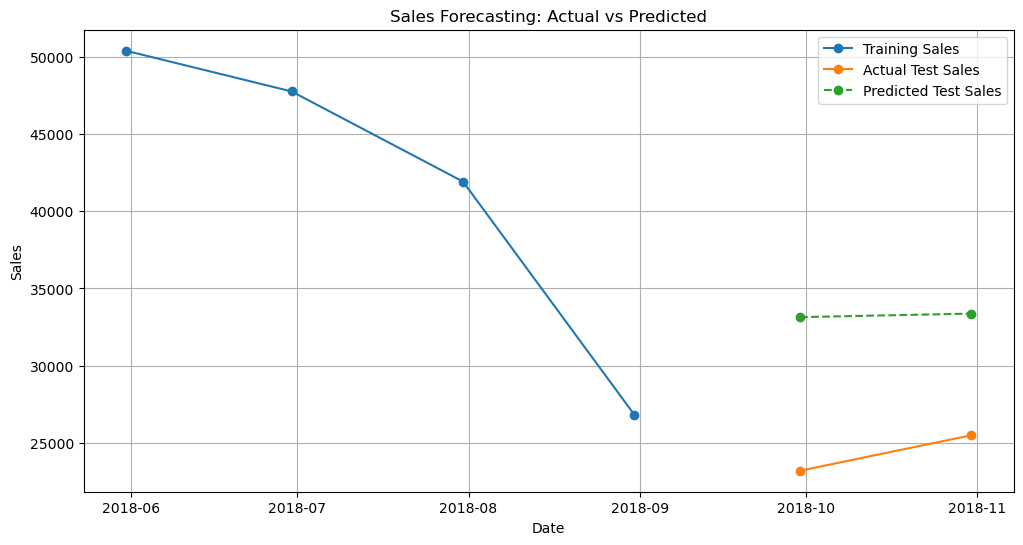


Next 3 Months Forecast
        Date  Forecasted_Sales
0 2018-11-30          33373.10
1 2018-12-31          33373.10
2 2019-01-31          40445.32


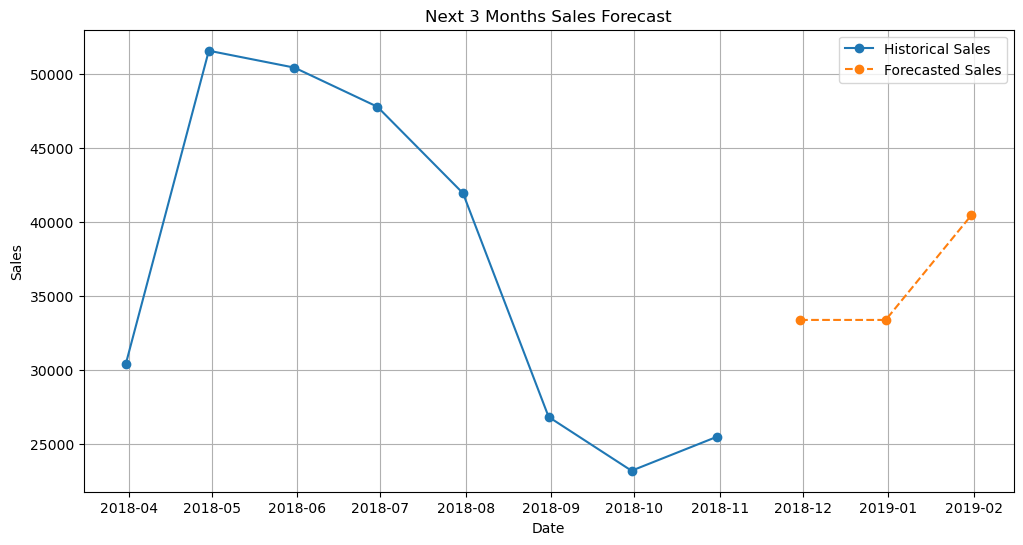

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

file_path = "powerbi_sales_dataset.csv"
df = pd.read_csv(file_path)

df.columns = df.columns.str.strip()

df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"], format="%d-%b-%y", errors="coerce")
if df["ORDERDATE"].isna().sum() > 0:
    df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"], errors="coerce", format="mixed")

df["SALES"] = pd.to_numeric(df["SALES"], errors="coerce")
df = df.dropna(subset=["ORDERDATE", "SALES"]).copy()
df = df.sort_values("ORDERDATE")

monthly_sales = (
    df.groupby(pd.Grouper(key="ORDERDATE", freq="ME"))["SALES"]
    .sum()
    .reset_index()
)

monthly_sales.columns = ["Date", "Sales"]
monthly_sales = monthly_sales.sort_values("Date")

print("Number of monthly observations:", len(monthly_sales))
print(monthly_sales.head())

# -----------------------------
# CASE 1: VERY SMALL DATASET
# -----------------------------
if len(monthly_sales) < 8:
    print("\nVery limited history detected.")
    print("Using simple 3-month moving average forecast instead of ML.")

    forecast_values = []
    history = monthly_sales["Sales"].tolist()
    last_date = monthly_sales["Date"].max()

    for i in range(3):
        if len(history) >= 3:
            pred = np.mean(history[-3:])
        else:
            pred = np.mean(history)

        next_date = last_date + pd.offsets.MonthEnd(1)
        forecast_values.append([next_date, round(pred, 2)])

        history.append(pred)
        last_date = next_date

    forecast_df = pd.DataFrame(forecast_values, columns=["Date", "Forecasted_Sales"])

    plt.figure(figsize=(12, 6))
    plt.plot(monthly_sales["Date"], monthly_sales["Sales"], label="Historical Sales", marker="o")
    plt.plot(forecast_df["Date"], forecast_df["Forecasted_Sales"], label="Forecasted Sales", marker="o", linestyle="--")
    plt.title("Sales Forecast with Small Dataset")
    plt.xlabel("Date")
    plt.ylabel("Sales")
    plt.legend()
    plt.grid(True)
    plt.show()

    print("\nForecast:")
    print(forecast_df)

# -----------------------------
# CASE 2: ENOUGH DATA FOR ML
# -----------------------------
else:
    monthly_sales["Month"] = monthly_sales["Date"].dt.month
    monthly_sales["Quarter"] = monthly_sales["Date"].dt.quarter
    monthly_sales["Year"] = monthly_sales["Date"].dt.year

    monthly_sales["Lag_1"] = monthly_sales["Sales"].shift(1)
    monthly_sales["Lag_2"] = monthly_sales["Sales"].shift(2)
    monthly_sales["Rolling_Mean_2"] = monthly_sales["Sales"].shift(1).rolling(2).mean()

    model_df = monthly_sales.dropna().copy()

    split_index = int(len(model_df) * 0.8)
    train_df = model_df.iloc[:split_index].copy()
    test_df = model_df.iloc[split_index:].copy()

    feature_cols = ["Month", "Quarter", "Year", "Lag_1", "Lag_2", "Rolling_Mean_2"]

    X_train = train_df[feature_cols]
    y_train = train_df["Sales"]
    X_test = test_df[feature_cols]
    y_test = test_df["Sales"]

    model = RandomForestRegressor(n_estimators=200, max_depth=5, random_state=42)
    model.fit(X_train, y_train)

    test_df["Predicted_Sales"] = model.predict(X_test)

    mae = mean_absolute_error(y_test, test_df["Predicted_Sales"])
    rmse = np.sqrt(mean_squared_error(y_test, test_df["Predicted_Sales"]))

    print("\nModel Performance")
    print(f"MAE  : {mae:.2f}")
    print(f"RMSE : {rmse:.2f}")

    plt.figure(figsize=(12, 6))
    plt.plot(train_df["Date"], train_df["Sales"], label="Training Sales", marker="o")
    plt.plot(test_df["Date"], test_df["Sales"], label="Actual Test Sales", marker="o")
    plt.plot(test_df["Date"], test_df["Predicted_Sales"], label="Predicted Test Sales", marker="o", linestyle="--")
    plt.title("Sales Forecasting: Actual vs Predicted")
    plt.xlabel("Date")
    plt.ylabel("Sales")
    plt.legend()
    plt.grid(True)
    plt.show()

    future_forecasts = []
    history = monthly_sales.copy()

    for _ in range(3):
        next_date = history["Date"].max() + pd.offsets.MonthEnd(1)

        lag_1 = history["Sales"].iloc[-1]
        lag_2 = history["Sales"].iloc[-2]
        rolling_mean_2 = history["Sales"].iloc[-2:].mean()

        next_input = pd.DataFrame({
            "Month": [next_date.month],
            "Quarter": [next_date.quarter],
            "Year": [next_date.year],
            "Lag_1": [lag_1],
            "Lag_2": [lag_2],
            "Rolling_Mean_2": [rolling_mean_2]
        })

        next_prediction = model.predict(next_input)[0]

        future_forecasts.append({
            "Date": next_date,
            "Forecasted_Sales": round(next_prediction, 2)
        })

        history = pd.concat([
            history,
            pd.DataFrame({"Date": [next_date], "Sales": [next_prediction]})
        ], ignore_index=True)

    forecast_df = pd.DataFrame(future_forecasts)

    print("\nNext 3 Months Forecast")
    print(forecast_df)

    plt.figure(figsize=(12, 6))
    plt.plot(monthly_sales["Date"], monthly_sales["Sales"], label="Historical Sales", marker="o")
    plt.plot(forecast_df["Date"], forecast_df["Forecasted_Sales"], label="Forecasted Sales", marker="o", linestyle="--")
    plt.title("Next 3 Months Sales Forecast")
    plt.xlabel("Date")
    plt.ylabel("Sales")
    plt.legend()
    plt.grid(True)
    plt.show()